# Xác suất, MLE và MAP (Probability, Maximum Likelihood & A Posteriori)

Mọi mô hình học máy đều mang tính bất định. Chúng ta không bao giờ chắc chắn 100% về dữ liệu, nên Xác suất là công cụ để định lượng sự không chắc chắn đó. Hai phương pháp cốt lõi để ước lượng tham số mô hình $\theta$ (ví dụ: trọng số $w$ trong hồi quy) là MLE và MAP.

**1. Ước lượng hợp lý cực đại (Maximum Likelihood Estimation - MLE):**
Mục tiêu của MLE là tìm bộ tham số $\theta$ sao cho **dữ liệu quan sát được có khả năng xảy ra cao nhất** (Likelihood).
$$\theta_{MLE} = \arg\max_{\theta} P(X | \theta)$$
Để tránh tràn số khi nhân nhiều xác suất, ta dùng hàm Log-Likelihood (LL):
$$\theta_{MLE} = \arg\max_{\theta} \sum_{i=1}^N \log P(x_i | \theta)$$
*Thực tế:* Cực tiểu hóa Mean Squared Error (MSE) trong Hồi quy tuyến tính hoàn toàn tương đương với MLE khi giả định nhiễu tuân theo phân phối Chuẩn.

**2. Ước lượng hậu nghiệm cực đại (Maximum A Posteriori - MAP):**
MAP mở rộng MLE bằng cách đưa thêm **niềm tin ban đầu (Prior)** về tham số $\theta$ thông qua định lý Bayes:
$$\theta_{MAP} = \arg\max_{\theta} P(X | \theta) P(\theta)$$
Chuyển sang dạng Log:
$$\theta_{MAP} = \arg\max_{\theta} \left( \sum_{i=1}^N \log P(x_i | \theta) + \log P(\theta) \right)$$
*Thực tế:* 
- Nếu $P(\theta)$ là phân phối Chuẩn (Gaussian), MAP tương đương với **Ridge Regularization (L2)**.
- Nếu $P(\theta)$ là phân phối Laplace, MAP tương đương với **Lasso Regularization (L1)**.

In [1]:
import numpy as np

# 1. Sinh dữ liệu giả định tuân theo phân phối Chuẩn (Gaussian)
# Ví dụ: Chiều cao của 1000 sinh viên, kỳ vọng thật = 170cm, độ lệch chuẩn thật = 5cm
np.random.seed(42)
true_mu, true_sigma = 170.0, 5.0
X = np.random.normal(true_mu, true_sigma, 1000)

# 2. Xây dựng hàm tính Log-Likelihood cho phân phối Chuẩn
def gaussian_log_likelihood(mu, sigma, data):
    N = len(data)
    # LL = -N/2 * log(2*pi*sigma^2) - 1/(2*sigma^2) * sum((x - mu)^2)
    ll = - (N / 2.0) * np.log(2 * np.pi * (sigma ** 2)) \
         - (1.0 / (2 * (sigma ** 2))) * np.sum((data - mu) ** 2)
    return ll

# 3. Tính toán MLE giải tích
# Theo toán học, MLE của kỳ vọng (mu) chính là trung bình mẫu (sample mean)
# MLE của phương sai (sigma^2) chính là phương sai mẫu chưa hiệu chỉnh
mu_mle = np.mean(X)
sigma_mle = np.std(X) # std tính theo N, không phải N-1

print("--- Ước lượng hợp lý cực đại (MLE) ---")
print(f"Tham số thực: mu = {true_mu}, sigma = {true_sigma}")
print(f"Tham số MLE : mu = {mu_mle:.4f}, sigma = {sigma_mle:.4f}")
print(f"Log-Likelihood lớn nhất đạt được: {gaussian_log_likelihood(mu_mle, sigma_mle, X):.4f}")

--- Ước lượng hợp lý cực đại (MLE) ---
Tham số thực: mu = 170.0, sigma = 5.0
Tham số MLE : mu = 170.0967, sigma = 4.8936
Log-Likelihood lớn nhất đạt được: -3006.8731


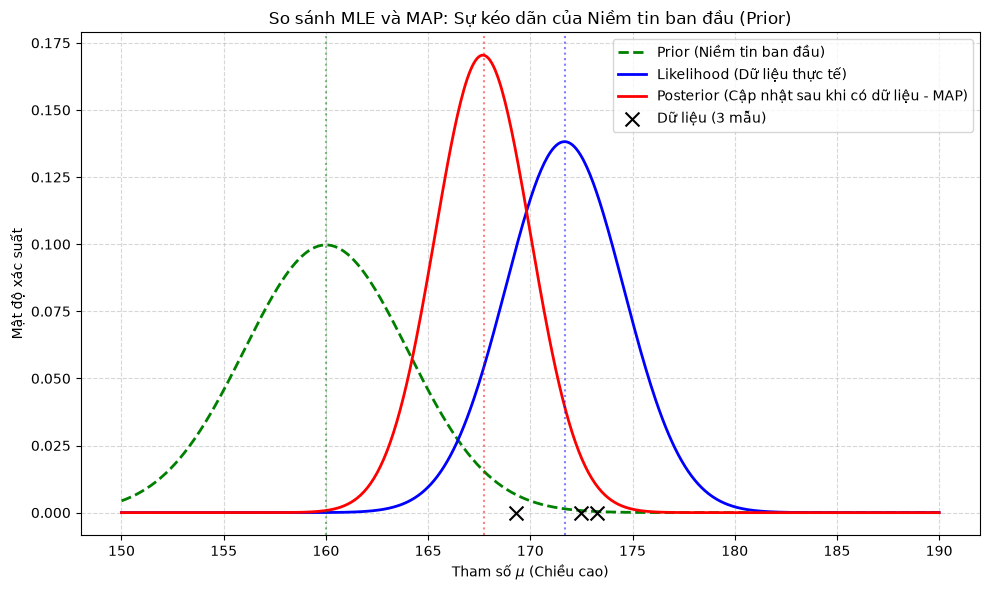

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# 1. Thiết lập dữ liệu (Chỉ lấy 3 mẫu để thấy rõ sức mạnh của Prior - MAP)
np.random.seed(42)
X_small = np.random.normal(170, 5, 3) 
mu_mle = np.mean(X_small)

# 2. Giả định không gian tham số mu (sigma cố định = 5)
mu_range = np.linspace(150, 190, 500)
sigma_fixed = 5.0

# 3. Tính Likelihood P(X|mu)
likelihoods = np.array([np.exp(gaussian_log_likelihood(m, sigma_fixed, X_small)) for m in mu_range])
# Chuẩn hóa để vẽ đồ thị
likelihoods /= (np.sum(likelihoods) * (mu_range[1] - mu_range[0]))

# 4. Định nghĩa Prior P(mu) - Niềm tin ban đầu: Kỳ vọng mu ở mức 160 (Lệch so với thực tế)
prior_mu, prior_sigma = 160, 4.0
priors = stats.norm.pdf(mu_range, prior_mu, prior_sigma)

# 5. Tính Posterior P(mu|X) tỷ lệ thuận với Likelihood * Prior
posteriors = likelihoods * priors
posteriors /= (np.sum(posteriors) * (mu_range[1] - mu_range[0])) # Chuẩn hóa
mu_map = mu_range[np.argmax(posteriors)]

# 6. Trực quan hóa
plt.figure(figsize=(10, 6))

plt.plot(mu_range, priors, label='Prior (Niềm tin ban đầu)', color='green', linestyle='--', lw=2)
plt.plot(mu_range, likelihoods, label='Likelihood (Dữ liệu thực tế)', color='blue', lw=2)
plt.plot(mu_range, posteriors, label='Posterior (Cập nhật sau khi có dữ liệu - MAP)', color='red', lw=2)

plt.axvline(prior_mu, color='green', linestyle=':', alpha=0.5)
plt.axvline(mu_mle, color='blue', linestyle=':', alpha=0.5)
plt.axvline(mu_map, color='red', linestyle=':', alpha=0.5)

plt.scatter(X_small, np.zeros_like(X_small), color='black', marker='x', s=100, label='Dữ liệu (3 mẫu)', zorder=5)

plt.title("So sánh MLE và MAP: Sự kéo dãn của Niềm tin ban đầu (Prior)")
plt.xlabel("Tham số $\mu$ (Chiều cao)")
plt.ylabel("Mật độ xác suất")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()